# Linear Regression

## First part - Necessary Code

In [1]:
import numpy as np
import json
import pandas as pd
import seaborn as sns
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

In [2]:
# Import company colors
with open('plot_colors.json', 'r') as pc:
    color_dict = json.load(pc)

c_light, c_dark, c_blue = color_dict['color_light'], color_dict['color_dark'], color_dict['color_blue']

# Define color map for plotting
color_map = ListedColormap([c_blue, c_light, c_dark])

### Linear regression equation plot

In [3]:
def linear_eq(annotate=False):

    plt.rcParams.update({'font.size': 15})

    # Generate x values
    x = np.linspace(0, 10, 100)

    # Calculate y values
    y = 2 + 1/3 * x
    circle1 = plt.Circle((3, 3), 0.15, color='orange', fill=True)
    circle2 = plt.Circle((6, 4), 0.15, color='orange', fill=True)


    plt.gca().add_patch(circle1)
    plt.gca().add_patch(circle2)

    # Create the plot
    plt.plot(x, y)

    # Add labels and title
    plt.xlim(0,7)
    plt.ylim(0.6)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.grid()

    if annotate:
        # Annotate the intercept
        plt.annotate('y-intercept',
                     xy=(0, 2),
                     xytext=(-90, 30),
                     textcoords='offset points',
                     arrowprops=dict(arrowstyle='->'))

        # Annotate general equation
        plt.annotate(r'$ y = b_0 + b_1*x $',
                     xy=(7, 4.2),
                     xytext=(5, 5),
                     textcoords='offset points')

        # Annotate slope
        plt.annotate(r'$ b_1 = \frac{\Delta y}{\Delta x}$',
                     xy=(7, 2.5),
                     xytext=(5, 5),
                     textcoords='offset points')

        # Annotate equation
        plt.annotate(r'Equation : $ y = 2 + \frac{1}{3}*x$',
                     xy=(7, 0.8),
                     xytext=(8, 8),
                     textcoords='offset points')
        
        # Annotate delta x and y arrows
        arrowstyle1 = FancyArrowPatch((6, 3), (6, 4),
                                 connectionstyle="arc3,rad=0.2", arrowstyle='<->, head_width=0.3',
                                 lw=1.5, mutation_scale=10, color='black')
        plt.gca().add_patch(arrowstyle1)
        
        arrowstyle2 = FancyArrowPatch((3, 3), (6, 3),
                                 connectionstyle="arc3,rad=0.2", arrowstyle='<->, head_width=0.3',
                                 lw=1.5, mutation_scale=10, color='black')
        
        plt.gca().add_patch(arrowstyle2)
        
        plt.annotate(r'$ \Delta y $',
             xy=(6.1, 3.3),
             xytext=(6.1, 3.3),
             textcoords='offset points')
        plt.annotate(r'$ \Delta x $',
             xy=(4.1, 2.3),
             xytext=(4.1, 2.3),
             textcoords='offset points')

    # Display the plot
    #plt.show()

### Linear regression example plot

In [4]:
def generate_data(num_points):
    np.random.seed(4)
    x = np.random.uniform(low=0, high=12, size=num_points)
    noise = np.random.normal(loc=0, scale=0.8, size=num_points)
    y = 0.3 + 0.5 * x + noise
    x = x[y > 0]
    y = y[y > 0]
    X = np.column_stack((np.ones(len(x)), x))
    feature_columns = pd.Index(['intercept', 'Week of bootcamp'])
    X_df = pd.DataFrame(X, columns=feature_columns)
    X_df['Coffee consumption in [l]'] = y
    return X_df, X, y.reshape(-1, 1)

num_points=50
data, X, y = generate_data(num_points)


In [5]:
data_lines = data.copy()

x_mean = data_lines['Week of bootcamp'].mean()
y_mean = data_lines['Coffee consumption in [l]'].mean()

reg_line_columns = pd.Index([
    'b1',
    'b0',
    'p_at_0',
    'p_at_12',
    'sum_of_squared_residuals',
    'sum_of_residuals',
])
reg_lines = pd.DataFrame(columns=reg_line_columns)

for b1 in [0.1, 0.3, 0.4, 0.5, 0.6, 0.8, 1]:
    # for each scope calculate a so every line goes through the mean of the data points
    b0 = y_mean - b1*x_mean
    
    # getting the plotting points at x = 1 and x = 11 (to define a line)
    p1 = b0 + b1*0
    p2 = b0 + b1*12
    
    data_lines.loc[:,f'prediction_b_{b1}'] = b0 + b1 * data_lines['Week of bootcamp']
    data_lines[f"residuals_{b1}_sq"]= (data_lines['Coffee consumption in [l]'] - data_lines[f'prediction_b_{b1}'])**2
    data_lines[f"residuals_{b1}"]= (data_lines['Coffee consumption in [l]'] - data_lines[f'prediction_b_{b1}'])
    ssr = sum(data_lines[f"residuals_{b1}_sq"])
    sr = sum(data_lines[f"residuals_{b1}"])
    
    reg_lines.loc[len(reg_lines.index)] = [b1, b0, p1, p2,  ssr, sr]


### Plot data

In [6]:
def plot_data(x, y, reg_data=None, figsize=(10,6), regression_line=False, residuals=False, line_selection=None, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    
    sns.set_context("talk", font_scale=0.8, rc={"lines.linewidth": 2.})
    
    # Plot scatter and regression line if set to True
    sns.regplot(x=x, y=y, scatter_kws={'s':30, "alpha": 1, "color": c_blue},
                ci=None, color=c_light, fit_reg=regression_line, ax=ax)
    
    if residuals:
        b1, b0 = np.polyfit(x, y, 1)
        regression_line = b0 + b1*x
        for i in range(len(x)):
            ax.plot([x[i], x[i]], [y[i], regression_line[i]], color=c_dark, linewidth=1)
            
    if isinstance(reg_data, pd.DataFrame):
        colors=["#191970", "#3765b5", "#617baa", "#bac2ca", "#617baa", "#191970", "#570f4c"]
        if line_selection is not None:
            for j, line in reg_data.iterrows():
                if j in line_selection:
                    ax.plot([0, 12], [line["p_at_0"], line["p_at_12"]], color=colors[j], linewidth=2)
        else:
            for j, line in reg_data.iterrows():
                ax.plot([0, 12], [line["p_at_0"], line["p_at_12"]], color=colors[j], linewidth=2)

    
    ax.set_xlabel('Week of bootcamp')
    ax.set_ylabel('Coffee consumption [l]')
    sns.despine()

### Fitted lines with residuals plot

In [7]:
def plot_possible_lines_with_residuals(x, y, reg_data=None, figsize=(10,6), line_index=3, residuals=False, ssr=False, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    
    sns.set_context("talk", font_scale=0.8, rc={"lines.linewidth": 2.})
    
    # Plot scatter and regression line if set to True
    sns.regplot(x=x, y=y, scatter_kws={'s':30, "alpha": 1, "color": c_blue},
                ci=None, color=c_light, fit_reg=False, ax=ax)
    
    #colors = ['#570f4c', 'darkblue', '#bac2ca', 'grey', '#191970', '#907390', '#570f4c']
    colors=["#191970", "#3765b5", "#617baa", "#bac2ca", "#617baa", "#191970", "#570f4c"]
    
    ax.plot([0, 12],[reg_lines["p_at_0"][line_index], reg_lines["p_at_12"][line_index]], color=colors[line_index], linewidth=2)
    
    if residuals:
        if not isinstance(reg_data, pd.DataFrame):
            raise ValueError('reg_data must be a pandas DataFrame when residuals is True.')
        regression_line = reg_data.loc[line_index, 'b0'] + reg_data.loc[line_index, 'b1']*x
        for i in range(len(x)):
            ax.plot([x[i], x[i]], [y[i], regression_line[i]], color=c_dark, linewidth=1)
            
    if ssr:
        if not isinstance(reg_data, pd.DataFrame):
            raise ValueError('reg_data must be a pandas DataFrame when ssr is True.')
        ax.annotate(text=f"SSR = {reg_data.loc[line_index, 'sum_of_squared_residuals'].round(2)}",
        xy=(0, 7),
        xytext=(1, 2),
        textcoords='offset points')
            
    ax.set_xlabel('Week of bootcamp')
    ax.set_ylabel('Coffee consumption [l]')
    sns.despine()


### Additional linear-regression visualizations


In [ ]:
def calc_regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    residuals = y_true - y_pred
    mse = np.mean(residuals**2)
    rmse = np.sqrt(mse)
    sst = np.sum((y_true - y_true.mean())**2)
    r2 = 1 - np.sum(residuals**2) / sst
    return rmse, r2

def plot_baseline_vs_regression(x, y, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 5))

    x = np.asarray(x).reshape(-1)
    y = np.asarray(y).reshape(-1)

    sns.scatterplot(x=x, y=y, s=35, color=c_blue, alpha=0.95, ax=ax)

    y_mean = y.mean()
    ax.axhline(y_mean, color=c_dark, linestyle='--', linewidth=2, label='Mean baseline')

    b1, b0 = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 200)
    ax.plot(x_line, b0 + b1 * x_line, color=c_light, linewidth=3, label='Fitted regression')

    ax.set_xlabel('Week of bootcamp')
    ax.set_ylabel('Coffee consumption [l]')
    ax.set_title('Baseline (mean) vs fitted regression')
    ax.legend(frameon=False)
    sns.despine()


def plot_metric_comparison_for_two_lines(x, y, reg_data, line_a=1, line_b=3, ax=None):
    if ax is None:
        fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    x = np.asarray(x).reshape(-1)
    y = np.asarray(y).reshape(-1)

    labels = ['Line A', 'Line B']
    idxs = [line_a, line_b]

    rmse_vals, r2_vals = [], []
    for idx in idxs:
        b0 = reg_data.loc[idx, 'b0']
        b1 = reg_data.loc[idx, 'b1']
        pred = b0 + b1 * x
        rmse, r2 = calc_regression_metrics(y, pred)
        rmse_vals.append(rmse)
        r2_vals.append(r2)

    colors = [c_dark, c_light]

    ax[0].bar(labels, rmse_vals, color=colors)
    ax[0].set_title('RMSE (lower is better)')
    ax[0].set_ylabel('RMSE')

    ax[1].bar(labels, r2_vals, color=colors)
    ax[1].set_title('$R^2$ (higher is better)')
    ax[1].set_ylabel('$R^2$')
    ax[1].set_ylim(0, 1)

    sns.despine()



## Second part - Lecture

<div class="slide-title"> 
        
# Linear Regression
           
</div> 

Notes:
- Welcome and frame the topic: predicting continuous values from data.
- Today's focus: intuition, key equations, and interpretation.
- Heavy optimization details come later.


### Historical Origin: Regression to the Mean

<div class="group">
  <div class="text">

* In the 19th century, Francis Galton studied parent and child heights.
* He observed that extreme values tend to be followed by values closer to the average.
* He called this pattern <i>regression toward mediocrity</i> (now: regression to the mean).

<div class="alert alert-block alert-info">
<b>Why this matters:</b><br>
The term <b>regression</b> originally came from this statistical phenomenon, before modern ML usage.
</div>

  </div>
  <div class="images">
    <img src="../images/linear_regression/francis_galton_1850s.jpg" width="320"><br>
    <small>Francis Galton (via Wikipedia/Wikimedia Commons)</small>
  </div>
</div>



Notes:
- Keep this short (historical context, not deep theory).
- Core intuition: extreme observations are often followed by less extreme ones.
- Clarify that this does not imply causality; it is a statistical tendency.
- Transition: today we use regression to model and predict continuous outcomes.


## Motivation

Why linear regression matters in practice.


Notes:
- Start with relatable prediction problems (price, demand, energy use).
- Explain why "linear" is often the first useful baseline.
- Emphasize interpretability of coefficients.


### Goal of Regression

<div class="group">
  <div class="text">

* I own a house in King County.
* It has 3 bedrooms, 2 bathrooms, a 10,000 sqft lot, and is 10 km away from Bill Gates' mansion.
* I need a reliable estimate of what it is worth.

  </div>
  <div class="images">
    <img src="../images/linear_regression/img_p3_1.png">
  </div>

</div>


Notes:
- Map story to ML terms: target = house price, features = bedrooms, bathrooms, lot size, distance.
- Highlight that features can have different units and scales.
- Regression learns the combined effect from historical data.


### How could I estimate the value?

<div class="group">
  <div class="text">

* Use training data to ...
* ... find one similar house ...
* ... and use its value as an estimate.
  </div>
  <div class="text">
* Use training data to ...
* ... learn a general rule ...
* ... and apply it to estimate value.
  </div>
</div>


Notes: A "general rule" is a regression model that quantifies a response variable (`y`) using a predictor variable (`x`).


### I should train a regression model

```
    216 645  $ base price

+    20 033  $ for each bedroom

+   234 314 $ for each bathroom

+         1 $ for each sqft of lot size

-    14 745 $ for each km distance from Bill Gates' mansion

=        xyz $ estimated house price
```

<div class="alert alert-block alert-info">
<b>Note:</b><br>
    The term regression (e.g. regression analysis) usually
    refers to <i>linear</i> regression.<br>
    (Don't confuse it with <i>logistic</i> regression.)
</div>


Notes: This "formula" is one possible kind of model, representing a certain aspect of reality.


### Building a model

<div class="group">
  <div class="text">
  <h4> Descriptive statistics </h4>
  Using linear regression for explanation (profiling)

  $\rightarrow$ Why is my house worth xyz?

  $\rightarrow$ How can I increase the price?

  <h4> Inferential statistics </h4>
  Using linear regression for prediction

  $\rightarrow$ How much is my house worth?


  </div>
  <div class="images">
    <img src="../images/linear_regression/img_p6_1.png">
  </div>

</div>



Notes: There are two broad methods in statistics:  
- descriptive ($\rightarrow$ EDA) and  
- inferential ($\rightarrow$ ML)



## Linear Equation

Notes:
- Transition: from motivation to the core equation behind the model.
- Remind students a straight line has two key parts: intercept and slope.


### Linear Equation
#### Question: What is the equation of a line?


Notes:
- Ask students to recall: what happens to `y` when `x` increases by 1?
- Connect that answer directly to slope `b1`.
- Use the plot to show intercept as the value at `x = 0`.


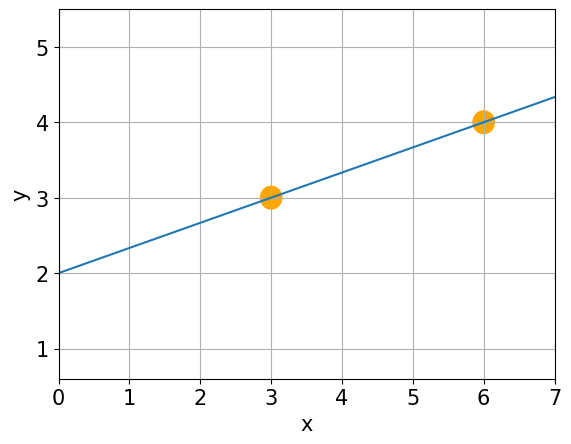

In [10]:
linear_eq()

### Linear Equation


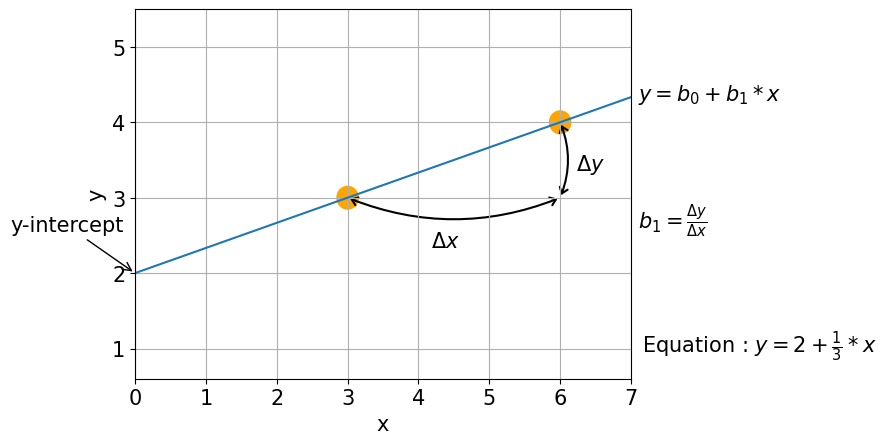

In [11]:
linear_eq(annotate=True)

<div class="alert alert-block alert-info">
<b>Key terms:</b>
<ul>
  <li>Intercept (<i>b</i><sub>0</sub>): predicted value of <i>y</i> when <i>x</i> = 0.</li>
  <li>Slope (<i>b</i><sub>1</sub>): expected change in <i>y</i> when <i>x</i> increases by 1 unit.</li>
</ul>
</div>






Notes: Show how to calculate slope and intercept for two points `(x1, y1)` and `(x2, y2)` (2 equations, 2 unknowns).


## Linear Regression

Notes:
- Transition: line equation was geometry, now we apply it to noisy real data.
- In practice, points are not exactly on one line, so we need a fitting rule.


### Linear Regression

* Is variable $X$ associated with variable $y$?

* If yes, what is the relationship, and can we use it to predict $y$?


<div class="alert alert-block alert-info">
<b>Note:</b><br>
<ul>
  <li>Correlation &mdash; measures the strength of a relationship &rarr; a number.</li>
  <li>Regression &mdash; quantifies the relationship itself &rarr; an equation.</li>
</ul>
</div>





Notes:
- Distinguish two questions:
  * Is there a relationship? (correlation)
  * What is the predictive equation? (regression)
- Mention that strong correlation does not automatically imply causation.


### What about more than 2 points?

<center>
<img src="../images/linear_regression/img_p14_1.png" width=600>  
</center>

Notes:  
Let students suggest some regressions (draw into zoom window).  
Would a non-linear model be sensible?  
Are the suggestions of different quality?  
What is the line good for?   
$\rightarrow$ we need a quantitative measure to decide what is "good".


### Let’s look at an example

<div class="group">
  <div class="text">

<b>Two correlated variables:</b>

* week of bootcamp, $x$
* coffee consumption, $y$
* $r \approx 0.9$
  </div>

  <div class="images">

$y = b_{0}+b_{1}\cdot x+e$

$\rightarrow$ Find $b_0$ and $b_1$
  </div>
</div>






Notes:
- Explain that this is a simple teaching example with synthetic data.
- Goal is not coffee itself; goal is understanding how fitting works.
- Point out that $r \approx 0.9$ suggests a strong linear pattern.



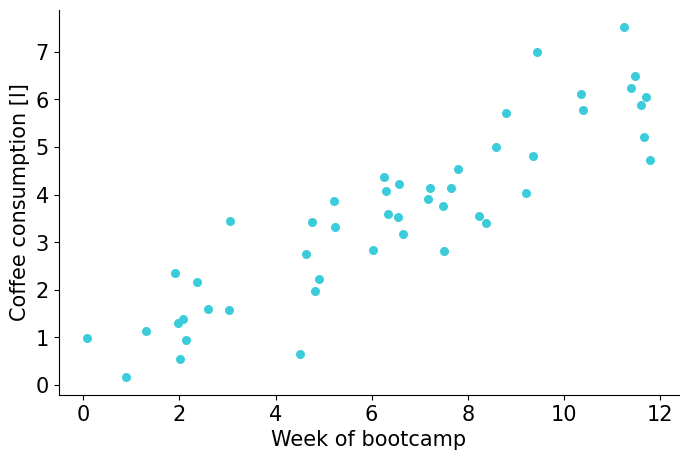

In [12]:
plot_data(data['Week of bootcamp'], data['Coffee consumption in [l]'], figsize=(8,5))

### Try two fitted lines. Which one is better?

* Grey: $\hat{y} = 0.35 + 0.5 \cdot x$
* Blue: $\hat{y} = 1.65 + 0.3 \cdot x$

<div class="alert alert-block alert-info">
<b>Note:</b> <br>
    <i>y&#770;</i> ("y-hat") denotes an estimated value (line) rather than an observed value (data point).
</div>






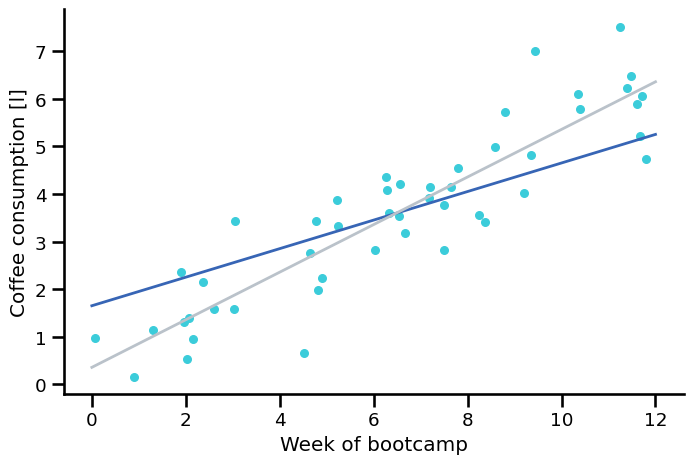

In [13]:
plot_data(data['Week of bootcamp'], data['Coffee consumption in [l]'], figsize=(8,5), reg_data=reg_lines, line_selection=[1, 3])

Notes:
- Remind students that the line is the model and the points are reality.
- The model deviates from the data, not the other way around.
- Residuals measure that deviation.


### How do we know which line is better?

Notes:
- Ask students to vote which line looks better before showing formulas.
- Use that moment to motivate the need for an objective numeric criterion.


### Residuals

For each observation $i$:

$$e_i = y_i - \hat{y}_i$$

which means:

$$y_i = b_0 + b_1 \cdot x_i + e_i$$

How to read this:
- Real value (what we observed): $y_i$
- Predicted value from the line: $\hat{y}_i$
- Prediction error (residual): $e_i$
- If the residual is positive ($e_i$ > 0), we predicted too low; if negative ($e_i$ < 0), we predicted too high.




Notes:
- Define residual as: observed minus predicted.
- Keep sign interpretation explicit: positive = underestimation, negative = overestimation.
- Link formula to the vertical distance shown in the plot.


### Residual Example (One Data Point)

Suppose for one observation:
- Observed value: $y = 4.8$
- Model prediction: $\hat{y} = 0.3 + 0.5 \cdot 6 = 3.3$

Residual:
$$e = y - \hat{y} = 4.8 - 3.3 = 1.5$$

Interpretation:
- Positive residual ($e > 0$): model underestimates
- Negative residual ($e < 0$): model overestimates


Notes:
- Walk through this slowly and write each number only once.
- Emphasize the order: residual = real minus predicted.
- Ask students what the sign means before revealing interpretation.
- Repeat: positive residual means the point lies above the line.


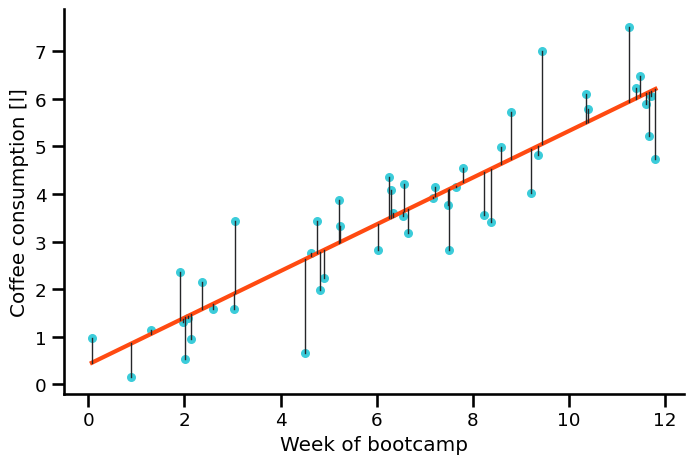

In [14]:
plot_data(data['Week of bootcamp'], data['Coffee consumption in [l]'], figsize=(8,5), regression_line=True, residuals=True)

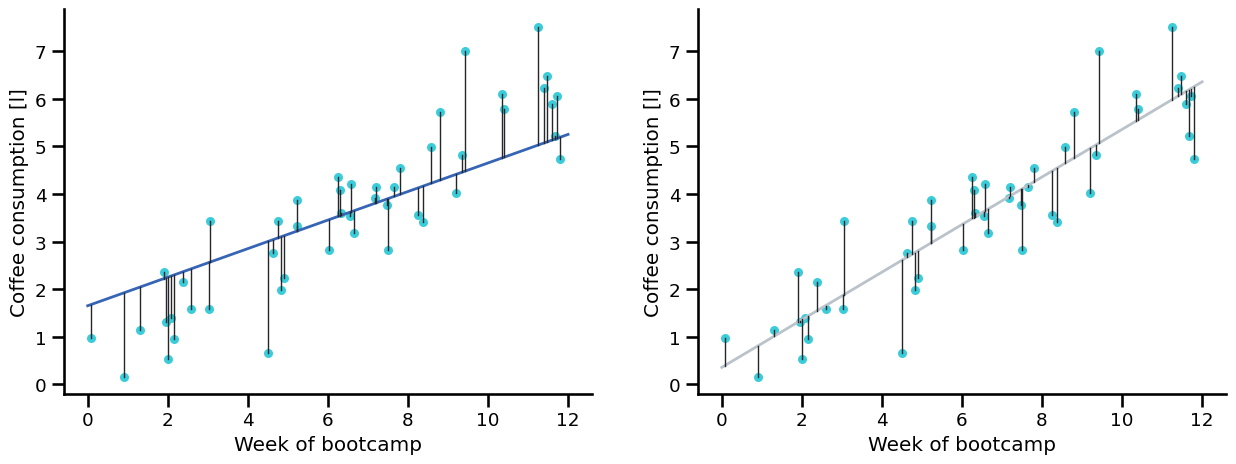

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15,5))
plot_possible_lines_with_residuals(data['Week of bootcamp'], data['Coffee consumption in [l]'], reg_lines, line_index=1, residuals=True, ax=ax[0])
plot_possible_lines_with_residuals(data['Week of bootcamp'], data['Coffee consumption in [l]'], reg_lines, line_index=3, residuals=True, ax=ax[1])

### Least Squares Criterion

To compare fitted lines, we use the sum of squared residuals:

$$ J(b_{0}, b_{1}) = \sum_{i=1}^{n} e_{i}^{2} = \sum_{i=1}^{n}(y_{i} - \hat{y}_{i})^{2} = \sum_{i=1}^{n}(y_{i} - (b_{0} + b_{1}x_{i}))^{2} $$

$$ n \text{ is the number of observations} $$

How to read this equation:
- Compute error for each point: $y_i-\hat{y}_i$
- Square each error (no cancellation, large errors count more)
- Add all squared errors $\rightarrow$ this total is $J$
- Smaller $J$ means a better-fitting line.





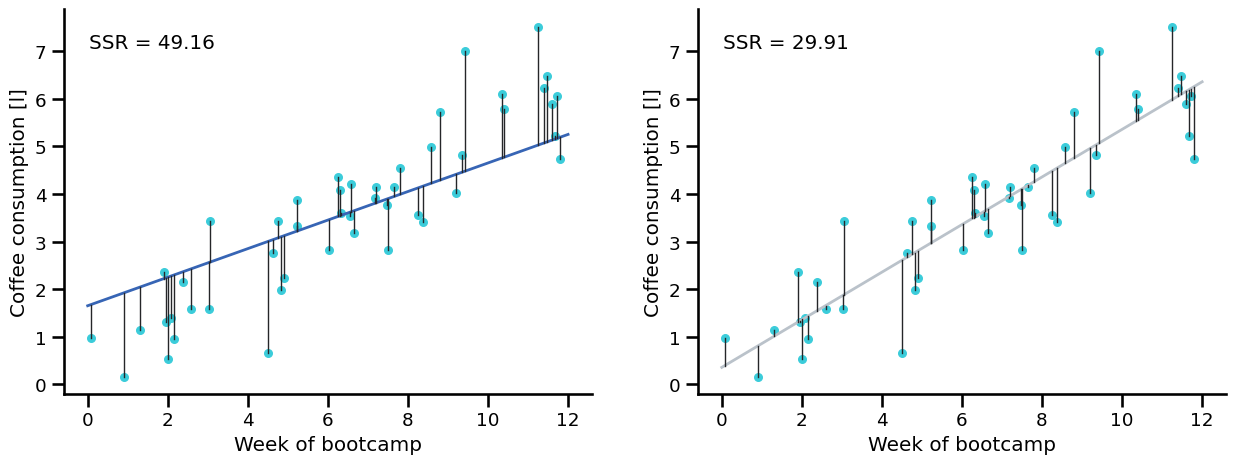

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(15,5))
plot_possible_lines_with_residuals(data['Week of bootcamp'], data['Coffee consumption in [l]'], 
                                   reg_lines, line_index=1, residuals=True, ssr=True, ax=ax[0])
plot_possible_lines_with_residuals(data['Week of bootcamp'], data['Coffee consumption in [l]'], 
                                   reg_lines, line_index=3, residuals=True, ssr=True, ax=ax[1])

Notes:
- Why not sum raw errors? Positive and negative errors can cancel out.
- Why square errors?
  * makes all contributions positive
  * penalizes large mistakes more strongly
  * gives a smooth function that is easy to optimize


### Trying several fitted lines

By comparing the sum of squared residuals, we can decide which line fits better:

$$ J(b_{0}, b_{1}) = \sum_{i=1}^{n} e_{i}^{2} = \sum_{i=1}^{n}(y_{i} - \hat{y}_{i})^{2} = \sum_{i=1}^{n}(y_{i} - (b_{0} + b_{1}x_{i}))^{2} $$

Beginner view:
- Each candidate line gets one score: $J$
- Lower score = line stays closer to points overall.




In [ ]:
fig, ax = plt.subplots(figsize=(8,5))
plot_data(
    data['Week of bootcamp'],
    data['Coffee consumption in [l]'],
    reg_data=reg_lines,
    residuals=False,
    ax=ax
)


Notes:
- Treat `J` as a "badness score" for the line.
- Changing slope/intercept changes this score.
- Goal: find parameters with the smallest possible score.
- For one feature, we can derive a closed-form solution.
- For many features, numerical optimization (for example, gradient descent) is often preferred.


### There are infinitely many possible lines


Notes: What does this mean?
We can evaluate how good a line is, but checking every possible line is not feasible.

The following slides can be shown briefly. The key message is that the objective function is a quantitative value we can optimize by choosing suitable `b0` and `b1` (later: Gradient Descent).


### So how do we solve this?

* Doing this manually is not scalable

* We minimize the <b>OLS</b> objective $J(b_0, b_1)$ with respect to $b_0$ and $b_1$

* <b>OLS</b> = Ordinary Least Squares

$$ J(b_{0}, b_{1}) = \sum (y_{i} - b_{0} - b_{1}x_{i})^{2} $$

Plain language:
- Try values for $b_0$ (intercept) and $b_1$ (slope)
- Keep the pair that makes $J$ as small as possible.





Notes:
- "Minimize" means: search for the smallest possible loss.
- `b0` shifts the line up/down.
- `b1` tilts the line.
- Together they control predictions and therefore residuals.


### Ordinary Least Squares Regression

$$ \mathrm{min}\ J(b_{0},b_{1})\ =\ \sum(y_{i}\ -\ b_{0}\ -\ b_{1}x_{i})^{2}$$


$$\begin{align}
\frac{\partial J}{\partial b_{0}}&=\mathrm{-2\,}\Sigma(y_{i}-b_{0}-b_{1}x_{i})\nonumber\,=\,0 \\
\frac{\partial J}{\partial b_{1}}&=\mathrm{-2\,}\Sigma x_i(y_{i}-b_{0}-b_{1}x_{i})\nonumber\,=\,0
\end{align}$$

Divide the first equation by $2n$:

$$ \begin{array}{c}{{-(\bar{y}\ -\ b_{0}\ -\ b_{1}\bar{x})\ =\ 0}} \\ {{b_{0}\ =\ \bar{y}\ -\ b_{1}\bar{x}}}\end{array}$$

... more algebra gives:

$$ b_1 = \frac{\Sigma(y_i - \bar{y})(x_i - \bar{x})}{\sum(x_{i} - \bar{x})^{2}} $$

<div class="alert alert-block alert-info">
<b>How to interpret:</b>
<ul>
  <li><i>&part;J/&part;b</i><sub>j</sub> means how much <i>J</i> changes when one parameter changes.</li>
  <li>Setting derivatives to 0 gives the minimum for this problem.</li>
  <li>Result: formulas for the best <i>b</i><sub>0</sub> and <i>b</i><sub>1</sub>.</li>
</ul>
</div>








Notes:
- Do not derive every algebra step in detail for beginners.
- Message to students: "We move parameters until loss stops improving."
- Partial derivative intuition:
  * positive derivative $\rightarrow$ move parameter down
  * negative derivative $\rightarrow$ move parameter up
  * zero derivative $\rightarrow$ best point (minimum here)
- Pronunciation guide for this slide:
  * $\partial$ = "partial"
  * $\Sigma$ = "capital sigma"
  * $\bar{y}$ = "y-bar"
- Emphasize: libraries compute this; students must understand the meaning.




### Useful facts about residuals

<div class="group">
  <div class="text">


$$\begin{align}
y_i &= b_0 + b_1 \cdot x_i + e_i \\
e_i &= y_i -b_0 -b_1 \cdot x_i \\
b_0 &= \bar{y} - b_1 \cdot \bar{x}
\end{align}$$

  </div>

  <div class="images">
Which leads to the following conclusions:

$$\begin{align}
\Sigma e_i &= 0 \\
\Sigma(x_i - \bar{x}) \cdot e_i &= 0
\end{align}$$
  </div>
</div>


<div class="alert alert-block alert-info">
<b>Note:</b>
<ul>
  <li>The second equation means residuals are uncorrelated with the explanatory variable.</li>
  <li>Feel free to verify this on your own fitted models.</li>
</ul>
</div>


Notes:
- Explain why these residual properties are useful checks for OLS.
- Intuition: over- and under-predictions balance out around zero.
- Residuals should not keep a linear pattern with `x` after fitting.


## Model performance

Notes:
- Reconnect to prior knowledge: average and spread.
- Mean = baseline prediction before using any feature.
- Variance = how much values naturally differ around the mean.


### Mean of target variable: $\bar{y}=\frac{1}{n} \sum\limits_{i=1}^{n}y_{i}$  
### Variance of target variable: $\sigma^2 = \frac{1}{n-1}\sum_i{(y_i-\bar{y})^2}$

How to read:
- <b>Mean</b>: add all target values and divide by how many values there are.
- <b>Variance</b>: average squared distance from the mean (how spread out values are).



Notes:
- Read both formulas slowly and define each symbol.
- Explain why variance uses squared distance from the mean.
- Clarify that `n - 1` is a degrees-of-freedom correction (sample variance).
- Pronunciation guide:
  * $\sigma^2$ = "sigma squared"
  * $\bar{y}$ = "y-bar"


### Baseline Mean vs Fitted Regression

A constant mean line is a simple baseline model.
A fitted regression line should reduce error compared with this baseline.


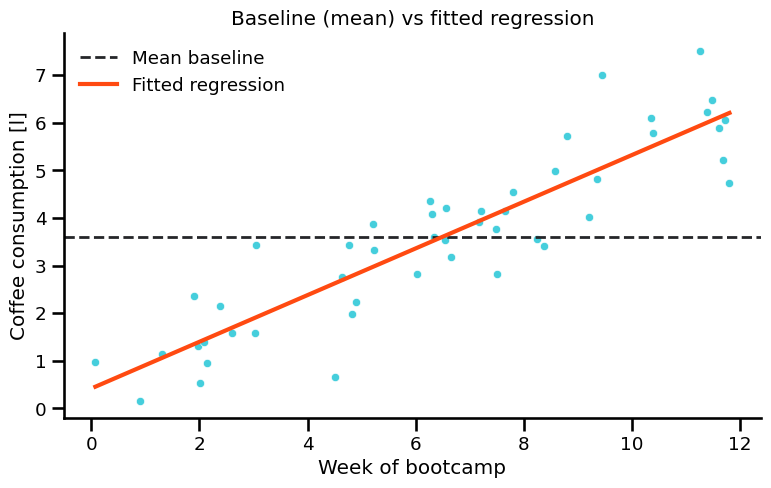

In [19]:
fig, ax = plt.subplots(figsize=(9,5))
plot_baseline_vs_regression(
    data['Week of bootcamp'],
    data['Coffee consumption in [l]'],
    ax=ax
)


Notes:
- The dashed line is the baseline: always predict the mean.
- The fitted line uses x-information and should follow the data better.
- This sets up why $R^2$ compares explained vs unexplained variance.


<div class="group">
  <div class="images">
    <img src="../images/linear_regression/mean_variance.png" width="1000">
  </div>

</div>

Notes:
- Baseline model: predict `y_bar` for everyone.
- If data points are very spread out, baseline errors are large.
- A good regression model should reduce error compared with this baseline.


### Sum of Squares Decomposition (Variance Analysis)

<div class="images">
  <img src="../images/linear_regression/variance_analysis.png" width="1000"><br>
</div>


**SST** = total sum of squares  
**SSE** = explained sum of squares  
**SSR** = residual (unexplained) sum of squares

$$SST = SSE + SSR$$

<div class="alert alert-block alert-info">
<b>Note:</b>
These quantities are scale-dependent, so their absolute values depend on the scale of <i>y</i>.<br>
0 &le; R<sup>2</sup> &le; 1<br>
R<sup>2</sup> = SSE / SST = 1 - SSR / SST<br>
Interpretation: higher R<sup>2</sup> means the model explains more of the target variability.
</div>

Notes:
- Start from baseline variability (SST).
- Regression splits it into:
  * explained part (SSE)
  * unexplained part (SSR)
- If SSR gets smaller, predictions improved.
- Then $R^2$ gets larger because more variance is explained.


### Root Mean Squared Error

$$ RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(y_{i}-{\hat{y}}_{i}\right)^{2}} $$

How to compute <b>RMSE</b>:
1. Compute each residual $(y_i-\hat{y}_i)$
2. Square residuals
3. Average them $\rightarrow$ <b>MSE</b>
4. Take square root $\rightarrow$ <b>RMSE</b>

<div class="alert alert-block alert-info">
<b>Note:</b> <br>
<b>RMSE</b> is in the same unit as <i>y</i> (easy to interpret).<br>
Lower <b>RMSE</b> means better predictions on average.
</div>








Notes:
- Emphasize workflow: residuals $\rightarrow$ square $\rightarrow$ average $\rightarrow$ square root.
- RMSE is easy to interpret because it uses the original target unit.
- Lower RMSE indicates better average predictive accuracy.



### Which Metric Answers Which Question?

- <b>RMSE</b>: "How large is the typical prediction error?"
  Units: same as target variable $y$

- <b>$R^2$</b>: "How much variance does the model explain?"
  Range: 0 to 1 (higher is better)

- <b>Adjusted $R^2$</b>: "Did extra features truly help?"
  Penalizes adding weak or unnecessary features



Notes:
- Give one plain-language question per metric.
- Suggest students report RMSE and adjusted $R^2$ together.
- RMSE gives practical error size; adjusted $R^2$ gives model-complexity awareness.
- Avoid claiming one metric is always enough.


### Metric Comparison for Two Candidate Lines

Same dataset, two fitted lines.
Use <b>RMSE</b> and $R^2$ to compare their quality directly.


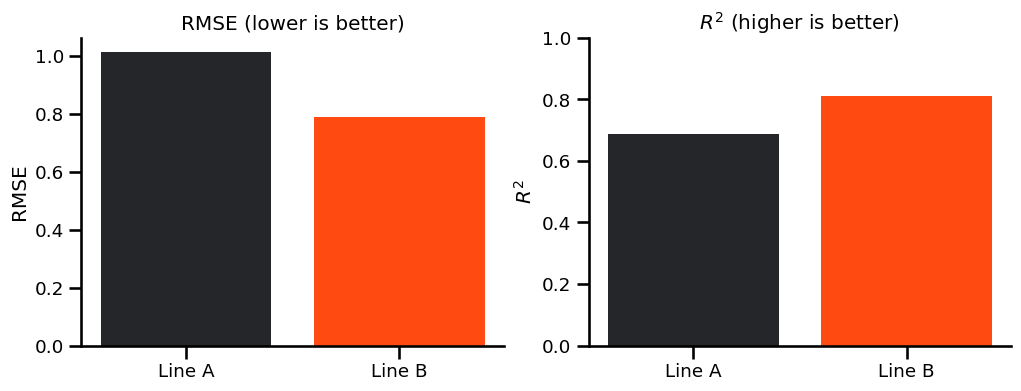

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
plot_metric_comparison_for_two_lines(
    data['Week of bootcamp'],
    data['Coffee consumption in [l]'],
    reg_lines,
    line_a=1,
    line_b=3,
    ax=ax
)

Notes:
- One model can look similar visually; metrics make the comparison explicit.
- Lower RMSE and higher $R^2$ should point to the better-fitting line.
- Reinforce: use multiple metrics, not only one number.


## Key Terms

Notes:
- Transition into terminology consolidation.
- Encourage students to focus on meaning, not memorizing every symbol at once.


### Key terms: Machine learning
#### Variables:
* Target (dependent variable, prediction, response, y)
* Feature (independent variable, explanatory/predictive variable, attribute, X)
* Observation (row, instance, example, data point)

#### Model:
* Fitted values (predicted values) - denoted with the hat notation $\hat{y}$
* Residuals (errors, e) - difference between reality and model
* Least squares (method for fitting a regression)
* Coefficients, weights (here: slope, intercept)


Notes: Clarify terminology. Different fields (statistics, engineering, economics) often use different names for the same concepts.


### But I want to use more than one feature


Notes:
- Transition from one-feature regression to real-world multi-feature models.
- Reassure students: same core idea, just matrix notation for efficiency.


## Multiple Linear Regression

Notes:
Transition point:
- Simple linear regression used one feature (`x`).
- Multiple linear regression uses many features (`x1`, `x2`, ..., `xm`).
- We keep one target variable for now.


### Multiple regression

For one feature: $y=b_0+b_1x+e$. For many features: $y=Xb+e$.

Where <b>y</b>, <b>b</b>, <b>e</b> are vectors, and <b>X</b> is a matrix.

$$
y = \begin{bmatrix} y_1 \\ \vdots \\ y_n \end{bmatrix},
\quad
X = \begin{bmatrix}
1 & x_{11} & \cdots & x_{1m} \\
\vdots & \vdots & \ddots & \vdots \\
1 & x_{n1} & \cdots & x_{nm}
\end{bmatrix}
$$

$$
b = \begin{bmatrix} b_0 \\ b_1 \\ \vdots \\ b_m \end{bmatrix},
\quad
e = \begin{bmatrix} e_1 \\ \vdots \\ e_n \end{bmatrix}
$$

$n$ = number of observations, $m$ = number of features.

$x_{obs,feature} = x_{row,col} = x_{n,m}$

$y$ and $X$ are known (observed data). $b$ and $e$ are unknown.

Think of $Xb$ as: for each row, multiply features by weights and add them up.

<div class="alert alert-block alert-info">
<b>Note:</b><br>
<i>Multiple</i> regression means multiple independent variables.
<i>Multivariate</i> regression means multiple dependent variables.
</div>



Notes (what to explain on this slide):
- Start from one-feature form `y = b0 + b1*x + e`, then generalize to `y = Xb + e`.
- Explain symbols in everyday language:
  * `y`: list of real target values
  * `X`: table of input features (rows = observations, columns = features)
  * `b`: model weights learned from data
  * `e`: leftover error after prediction
- Explain why first column of `X` is all ones: it allows intercept `b0`.
- Explain index notation: `x_ij` = feature `j` of observation `i`.
- Dimension sanity check: `Xb` must have the same shape as `y`.
- Terminology:
  * multiple regression $\rightarrow$ many input variables
  * multivariate regression $\rightarrow$ many output variables



Notes (quick example):
- House-price prediction with features: size, bedrooms, age, distance to city center.
- Each row in `X` is one house; each column is one feature.
- Model output: one predicted price per house (still one target variable).


### Normal Equation

The optimal values for $b$ ($b_0$, $b_1$, $...$, $b_m$) are often found numerically (e.g., gradient descent).
For linear regression, they can also be computed analytically with the normal equation:  

$$b = (X^TX)^{-1}X^Ty$$   (Moore-Penrose pseudoinverse)  

#### Predictions  
Once $b$ is known, we can make predictions:
$$ \hat{y} = b_0 + b_1x_1  + ... + b_mx_m $$  

Or in matrix notation:

$$\hat{y} = Xb$$  

$X$ needs the same feature format as above, but can have a different number of rows (e.g., 1).
The error term $e$ remains unknown, but is minimized during fitting.




Notes:
- This is the closed-form (analytic) solution for linear regression coefficients.
- In practice, libraries compute this for you.
- Emphasize when to use conceptually: matrix form of the same model, not a different model.


### Multiple Regression &mdash; Evaluation Metrics

#### Root Mean Squared Error (<b>RMSE</b>)

$$ RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(y_{i}-{\hat{y}}_{i}\right)^{2}} $$

&emsp; Typical prediction error size in the original unit of $y$.  
&emsp; Lower <b>RMSE</b> is better.

#### Adjusted R-squared ($adj.\ R^2$):
$$ adj.\;R^{2}=1-\left(1-R^{2}\right)\frac{n-1}{n-p-1}$$

&emsp; $n$: sample size, $p$: number of features.  
&emsp; Starts from $R^2$, then penalizes unnecessary features.

<div class="alert alert-block alert-info">
<b>Note:</b>
Use <b>RMSE</b> for error magnitude and adjusted R<sup>2</sup> to check if extra features are truly useful.
</div>







Notes:
- Explain why we need more than one metric.
- RMSE captures error magnitude; adjusted `R^2` balances fit and model complexity.
- Warn against adding features just to improve in-sample fit.


### Overview of Linear Regression Terms  

- $R$: Pearson correlation coefficient &mdash; in the interval [-1, 1]
- $R^2$: Coefficient of determination &mdash; fraction of variance in $y$ explained by the model
- $MSE$: mean squared error &mdash; average squared prediction error
- $RMSE$: root mean squared error &mdash; square root of MSE in the original unit of $y$
- $SST$, $SSE$, $SSR$: sum of squares &mdash; total, explained, residual
- $\sigma^2$: variance of a variable &mdash; dispersion around the mean

<div class="alert alert-block alert-info">
<b>Beginner shortcut</b>:
<ul>
  <li>Residuals tell you point-by-point errors.</li>
  <li>RMSE tells you average error size.</li>
  <li>R<sup>2</sup> tells you how much variance your model explains.</li>
</ul>
</div>







Notes:
- Use this slide as a quick recap and vocabulary check.
- Ask students to explain one metric in their own words.
- Reinforce how metrics relate: lower error often increases $R^2$.


## References  

There are also many detailed explanations in the exercise repositories.

[Practical Statistics for Data Science](https://www.oreilly.com/library/view/practical-statistics-for/9781491952955/) - Peter Bruce & Andrew
Bruce

[Econometric Methods with Applications in Business and
Economics](https://dl.rasabourse.com/Econometrics_Erasmus/Christiaan_Heij_Paul_de_Boer.pdf) - Christiaan Heij, Paul de Boer, Philip Hans
Franses, Teun Kloek, Herman K. van Dijk

[Written explanation of LR](https://learningstatisticswithr.com/book/regression.html)

[Difference between $R^2$ and adjusted $R^2$](https://www.investopedia.com/ask/answers/012615/whats-difference-between-rsquared-and-adjusted-rsquared.asp)  

[StatQuest: Linear Regression](https://www.youtube.com/watch?v=7ArmBVF2dCs)


Notes:
- Close with next steps: practice in exercises and apply metrics to real data.
- Suggest one reading/video as optional follow-up, not mandatory.


### Some more math for those who want to know how to calculate $b_1$

$-2 \Sigma x_i(y_i - b_0 - b_1x_i) = 0 $

we know that $b_0 = \bar{y} - b_1 \bar{x}$

$-2 \Sigma x_i(y_i - \bar{y} + b_1 \bar{x} - b_1x_i) = 0 $

$\Sigma(x_iy_i - x_i \bar{y} + b_1(x_i \bar{x} - x_ix_i)) = 0$

$\Sigma(x_iy_i - 2x_i \bar{y} + \bar{x}\bar{y} + b_1(-\bar{x}\bar{x} + 2x_i \bar{x} - x_ix_i)) = 0 \hspace{1cm}|\hspace{1cm} \Sigma x_i = \Sigma \bar{x} $

$\Sigma(x_iy_i - x_i \bar{y} - \bar{x}y_i + \bar{x}\bar{y} + b_1(-\bar{x}\bar{x} + 2x_i \bar{x} - x_ix_i)) = 0 \hspace{1cm}|\hspace{1cm} \Sigma x_i \bar{y}= \Sigma \bar{x}y_i = n \bar{x}\bar{y} $

$\Sigma(y_i - \bar{y})(x_i - \bar{x}) - b_1 \Sigma(x_i - \bar{x})^2 = 0 $

$b_1 = \frac{\Sigma(y_i - \bar{y})(x_i - \bar{x})}{\Sigma(x_i - \bar{x})^2} $

